# Unsupervised sweep results

Compare **KMeans+PCA** and **MFA-EM (HDDC)** using aggregated unsupervised evaluation reports.
This follows the structure of [Toy-manifold noise sweep results](toy_manifold_noise_sweep_results.ipynb):
load results, inspect K/threshold sweeps, select runs, compare geometry/ranks/counts, compare PC1 density support, export a heatmap, and plot coverage.
All panels use one dataset; neighboring-tile alignment replaces ground-truth tangent geometry.

Metric definitions and populations: [Unsupervised evaluation](../docs/evaluation/unsupervised.md).

## 1. Load the dataframe

`general_df` has one row per evaluated run. No `manifold_metrics.csv` is needed.
Set `DATA_DIR` to the folder for one dataset containing `general_metrics.csv`, produced with
`uv run --locked dalg-aggregate-metrics <folder>` after unsupervised evaluation.
Run this notebook from the repository root or `notebooks/`.

Choose one layer and optional experiment names below. Multiple seeds, capacities, or experiment variants
must be selected explicitly so each plotted cell represents one run. Missing or disabled metrics
are shown as gray **—** cells. Old reports need explicit reevaluation and CSV aggregation to add tile alignment or PC1 density.
For PC1 density, use `dalg-run-pipeline evaluate --manifest <manifest> --evaluation-kind unsupervised
--pc1-density --pc1-density-space pca75` with your usual device/coverage options, then aggregate again.
This notebook only reads saved results; it does not run evaluation.

In [2]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import display

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent

# Set this to your dataset folder containing general_metrics.csv.
DATA_DIR = REPO_ROOT / "dalg-cache/sae-manifold/sae_manifold_years_neutral_llama31_8b_last"
LAYER = 4  # Select 4 or 28; None selects the first available layer.
EXPERIMENTS = None  # e.g. ["sae_manifold_temperature_02d_hddc_em", "sae_manifold_temperature_02d_kmeans_pca"]
PC1_DENSITY_SPACE = "pca75"  # "pca75" or "ambient"; other-space density scores are shown as missing.
MODEL_NAMES = {"kmeans": "K-means + PCA", "hddc": "MFA-EM (HDDC)"}

directory = Path(DATA_DIR).resolve()
csv_path = directory / "general_metrics.csv"
if not csv_path.is_file():
    raise FileNotFoundError(f"Missing {csv_path}. Set DATA_DIR or run dalg-aggregate-metrics on this folder.")
general_df = pd.read_csv(csv_path)
general_df["report_path"] = general_df["source_path"].map(lambda value: str((directory / value).resolve()))
assert "evaluation" in general_df, "CSV lacks evaluation kind; reevaluate and aggregate current reports."
general_df = general_df.loc[general_df["evaluation"].eq("unsupervised")].copy()
general_df = general_df.loc[general_df["model_kind"].isin(MODEL_NAMES)].copy()
if "config.training.arguments.fit_method" in general_df:
    general_df = general_df.loc[
        ~general_df["model_kind"].eq("hddc")
        | general_df["config.training.arguments.fit_method"].eq("em")
    ].copy()
if EXPERIMENTS is not None:
    general_df = general_df.loc[general_df["config.identity.experiment"].isin(EXPERIMENTS)].copy()
assert not general_df.empty, "No unsupervised KMeans+PCA / MFA-EM reports match the selections."
assert not general_df["report_path"].duplicated().any(), "CSV includes duplicate reports."

# Dataset IDs come from pipeline specs; standalone reports use their shard path.
general_df["dataset_id"] = general_df.get("config.dataset.id", general_df["dataset.shard_dir"])
general_df["dataset_id"] = general_df["dataset_id"].fillna(general_df["dataset.shard_dir"])
available_layers = sorted(general_df["dataset.layer"].dropna().unique())
print("Available layers:", available_layers)
if LAYER is None:
    LAYER = available_layers[0]
general_df = general_df.loc[general_df["dataset.layer"].eq(LAYER)].copy()
assert not general_df.empty, f"No reports for layer {LAYER}."
assert general_df["dataset_id"].nunique(dropna=False) == 1, (
    "Select one dataset: set DATA_DIR to its results folder or restrict EXPERIMENTS."
)
DATASET = general_df["dataset_id"].iloc[0]

METRIC_COLUMNS = {
    "Mean qₖ": "rank.mean_learned",
    "NLL (validation)": "nll.validation",
    "Quantization MSE (validation)": "quantization.validation.mean_squared_distance",
    "Reconstruction MSE (validation)": "reconstruction.validation.mse",
    "Live / total components": "components.live",
    "Leading-PC alignment": "tile_alignment.leading_pc_alignment.mean",
    "Best-subset PC alignment": "tile_alignment.best_subset_pc_alignment.mean",
    "Median log PC1 retention": "pc1_density.log_retention.median",
    "Median log PC1 enrichment": "pc1_density.log_enrichment.median",
    "Adjusted BIC": "bic.value",
    "Regular BIC": "bic.standard_bic",
}
ALIGNMENT_METRICS = ["Leading-PC alignment", "Best-subset PC alignment"]
PC1_DENSITY_METRICS = ["Median log PC1 retention", "Median log PC1 enrichment"]
assert PC1_DENSITY_SPACE in {"pca75", "ambient"}
# MFA has no quantization score; KMeans has no NLL/BIC. Disabled blocks may be absent.
for column in METRIC_COLUMNS.values():
    if column not in general_df:
        general_df[column] = float("nan")
density_space_column = "pc1_density.settings.pc1_density_space"
if density_space_column not in general_df:
    general_df[density_space_column] = pd.NA
density_selected = general_df[density_space_column].eq(PC1_DENSITY_SPACE).fillna(False)
# Keep other metrics visible even when density was evaluated in a different space.
general_df.loc[~density_selected, [METRIC_COLUMNS[name] for name in PC1_DENSITY_METRICS]] = float("nan")
print(f"PC1 density space: {PC1_DENSITY_SPACE}; {int(density_selected.sum())} matching reports. "
      "Missing or other-space scores are shown as —.")
print(f"general_df: {len(general_df):,} runs at layer {LAYER}")
display(general_df[["dataset_id", "model_kind", "K", "q_capacity", "surgery_threshold"]].drop_duplicates())

Available layers: [np.int64(4), np.int64(28)]
PC1 density space: pca75; 16 matching reports. Missing or other-space scores are shown as —.
general_df: 16 runs at layer 4


/tmp/ipykernel_2710745/1829131697.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  general_df["report_path"] = general_df["source_path"].map(lambda value: str((directory / value).resolve()))


,dataset_id,model_kind,K,q_capacity,surgery_threshold
0,years_neutral,hddc,100,16,0.1000
1,years_neutral,hddc,100,16,0.0100
2,years_neutral,hddc,100,16,0.0010
3,years_neutral,hddc,100,16,0.0001
4,years_neutral,hddc,50,16,0.0010
5,years_neutral,hddc,50,16,0.0001
6,years_neutral,hddc,50,16,0.0100
7,years_neutral,hddc,50,16,0.1000
16,years_neutral,kmeans,100,26,0.0100
17,years_neutral,kmeans,100,34,0.0010


## 2. K and rank selection at a glance

Each figure fixes a model for the selected dataset, with **K on rows** and **surgery threshold on columns**.
Choose one MFA rank capacity; KMeans uses its saved cluster PCA. Lists control order and `None`
includes all available K values or thresholds. Duplicate configurations raise an error rather than averaging seeds.

- Mean qₖ uses all MFA components or PCA-valid KMeans components, including assignment-dead components.
- Alignment averages outgoing neighbors per eligible tile, then tiles equally. Both scores use a fixed 0–1 scale.
- PC1 density panels show medians of natural-log scores, centered at zero (ratio one), without a 0–1 bound.
  Retention is primary; enrichment compares with matched random directions. Positive values mean ratios above one.
  Density values are comparable only within the same data/split, density space, and estimator settings.
- Live-component labels show **live / K**, with color indicating percent live.
- Validation NLL, quantization MSE, reconstruction MSE, and regular BIC are brighter when lower; adjusted BIC is brighter when higher.
  NLL/BIC apply to MFA; quantization applies to KMeans. Mean rank has no preferred direction.
- Reconstruction MSE applies to both models and averages squared reconstruction error per activation dimension.
  It uses the MFA posterior mixture mean or the nearest-centroid retained PCA projection for KMeans;
  KMeans samples assigned to PCA-invalid components are excluded. Values use scientific notation.
- Compare fit/coverage within the same dataset, layer, preprocessing, and split. Adjusted BIC's activity reward depends on K.

In [3]:
SWEEP_MODELS = [model for model in MODEL_NAMES if general_df["model_kind"].eq(model).any()]
SWEEP_K_VALUES = None  # e.g. [50, 100, 250]
SWEEP_THRESHOLDS = None  # e.g. [0.0001, 0.001, 0.01, 0.1]
capacities = sorted(general_df.loc[general_df["model_kind"].eq("hddc"), "q_capacity"].dropna().unique())
SWEEP_Q_CAPACITY = capacities[0] if capacities else None  # Choose one MFA capacity.
SWEEP_METRICS = list(METRIC_COLUMNS)
print("Available MFA capacities:", capacities, "| selected:", SWEEP_Q_CAPACITY)

sweep_selected = general_df["model_kind"].isin(SWEEP_MODELS)
sweep_selected &= general_df["model_kind"].eq("kmeans") | general_df["q_capacity"].eq(SWEEP_Q_CAPACITY)
if SWEEP_K_VALUES is not None:
    sweep_selected &= general_df["K"].isin(SWEEP_K_VALUES)
if SWEEP_THRESHOLDS is not None:
    sweep_selected &= general_df["surgery_threshold"].isin(SWEEP_THRESHOLDS)
sweep_runs = general_df.loc[sweep_selected].copy()
assert not sweep_runs.empty, "No runs match the sweep selections."
assert sweep_runs["surgery_threshold"].notna().all(), "Sweep plots require saved surgery thresholds."
assert not sweep_runs.duplicated(["model_kind", "K", "surgery_threshold"]).any(), (
    "Each heatmap cell must select one run. Restrict EXPERIMENTS / capacities / seeds in the loading cell."
)
sweep_summary = sweep_runs.rename(columns={column: title for title, column in METRIC_COLUMNS.items()})
sweep_k_values = sorted(sweep_runs["K"].unique()) if SWEEP_K_VALUES is None else SWEEP_K_VALUES
sweep_tables = {}
for model in SWEEP_MODELS:
    thresholds = (sorted(sweep_runs.loc[sweep_runs["model_kind"].eq(model), "surgery_threshold"].unique())
                  if SWEEP_THRESHOLDS is None else SWEEP_THRESHOLDS)
    if not len(thresholds):
        continue
    rows = sweep_summary.loc[sweep_summary["model_kind"].eq(model)]
    sweep_tables[model] = {
        metric: rows.pivot(index="K", columns="surgery_threshold", values=metric).reindex(
            index=sweep_k_values, columns=thresholds,
        ) for metric in SWEEP_METRICS
    }
print(f"Selected {len(sweep_runs)} runs for {len(sweep_tables)} dashboards.")

Available MFA capacities: [np.int64(16)] | selected: 16
Selected 16 runs for 2 dashboards.


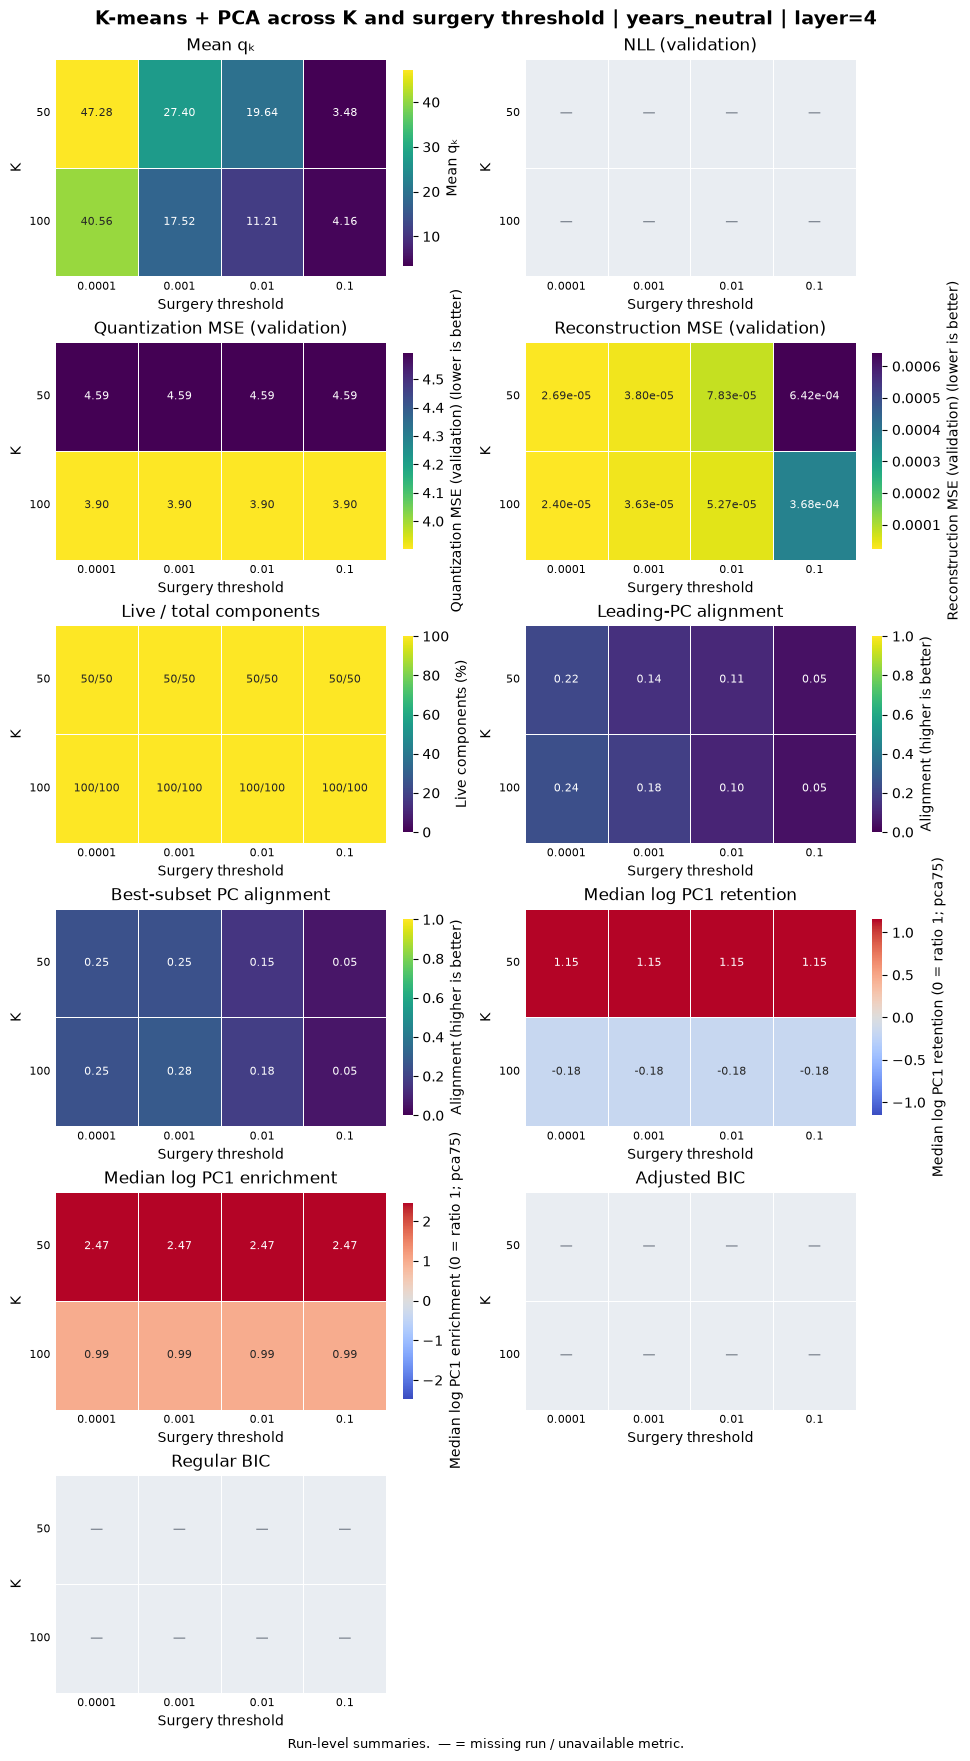

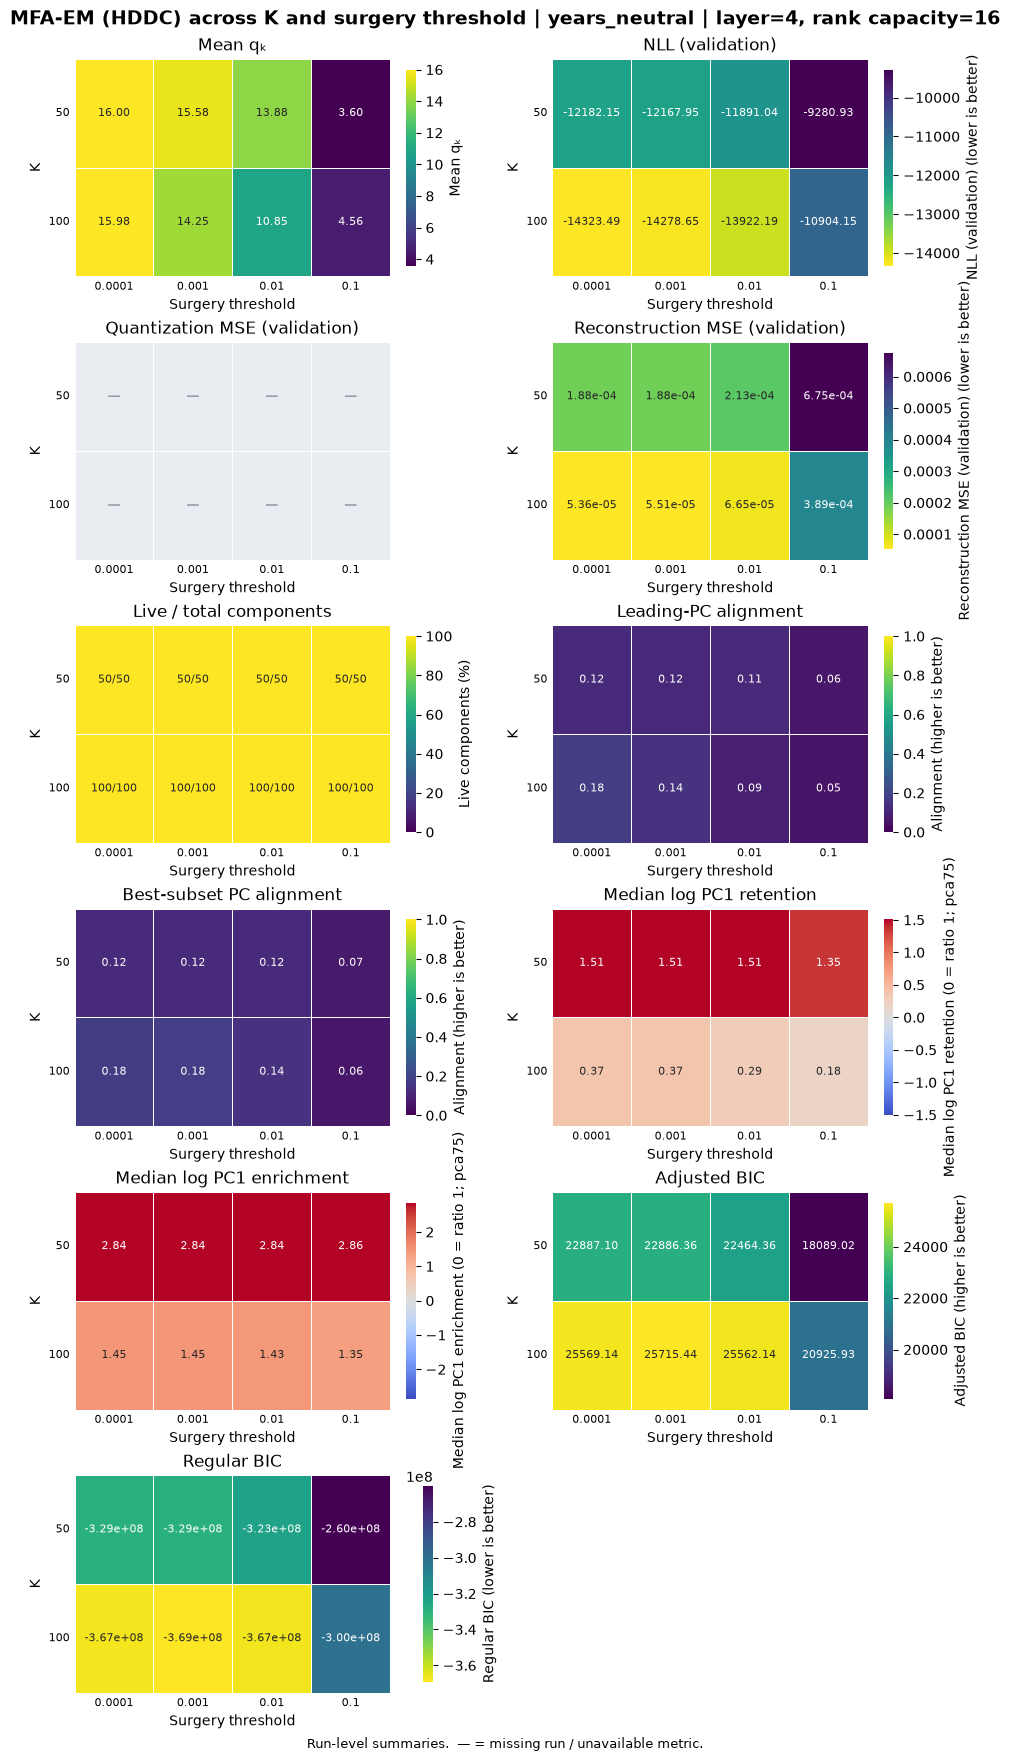

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

def plot_sweep_heatmap(ax, metric, table, model):
    """Draw one K/threshold panel with the dashboard scales and annotations."""
    values = table
    annotations = table.map(lambda value: f"{value:.2f}" if pd.notna(value) else "")
    cmap, vmin, vmax, color_label = "viridis", None, None, metric
    if metric == "Live / total components":
        values = table.div(table.index, axis="index") * 100
        vmin, vmax, color_label = 0, 100, "Live components (%)"
        annotations = table.copy().astype(object)
        for k in table.index:
            annotations.loc[k] = table.loc[k].map(lambda value: f"{int(value)}/{k}" if pd.notna(value) else "")
    elif metric in ALIGNMENT_METRICS:
        vmin, vmax, color_label = 0, 1, "Alignment (higher is better)"
    elif metric in PC1_DENSITY_METRICS:
        limit = table.abs().max().max()
        limit = float(limit) if pd.notna(limit) and limit > 0 else 1.0
        cmap, vmin, vmax = "coolwarm", -limit, limit
        color_label = f"{metric} (0 = ratio 1; {PC1_DENSITY_SPACE})"
    elif metric == "Adjusted BIC":
        color_label = "Adjusted BIC (higher is better)"
    elif metric in ["Regular BIC", "Reconstruction MSE (validation)"]:
        cmap, color_label = "viridis_r", f"{metric} (lower is better)"
        annotations = table.map(lambda value: f"{value:.2e}" if pd.notna(value) else "")
    elif metric in ["NLL (validation)", "Quantization MSE (validation)"]:
        cmap, color_label = "viridis_r", f"{metric} (lower is better)"
    # Supply a harmless scale when the entire panel is missing.
    if not values.notna().any().any() and vmin is None:
        vmin, vmax = 0, 1
    sns.heatmap(values, ax=ax, annot=annotations, fmt="", cmap=cmap, vmin=vmin, vmax=vmax,
                linewidths=0.5, linecolor="white", annot_kws={"fontsize": 8},
                xticklabels=[f"{value:g}" for value in table.columns],
                yticklabels=table.index, cbar=bool(values.notna().any().any()), cbar_kws={"label": color_label, "shrink": 0.9})
    ax.set_facecolor("#e9edf2")
    for row, col in np.argwhere(table.isna().to_numpy()):
        ax.text(col + 0.5, row + 0.5, "—", ha="center", va="center", color="#626b78", fontsize=9)
    ax.set(title=metric, xlabel="Surgery threshold", ylabel="K")
    ax.tick_params(axis="both", labelrotation=0, labelsize=8, length=0)


for model, tables in sweep_tables.items():
    ncols = min(2, len(tables))
    nrows = (len(tables) + ncols - 1) // ncols
    grid = next(iter(tables.values()))
    panel_width = max(4.8, 2 + 0.6 * len(grid.columns))
    panel_height = max(2.8, 1.4 + 0.4 * len(grid.index))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * panel_width, nrows * panel_height + 0.7),
                             squeeze=False, layout="constrained", facecolor="white")
    title = f"{MODEL_NAMES[model]} across K and surgery threshold | {DATASET} | layer={LAYER}"
    if model != "kmeans":
        title += f", rank capacity={SWEEP_Q_CAPACITY}"
    fig.suptitle(title, fontsize=14, fontweight="bold")

    for ax, (metric, table) in zip(axes.flat, tables.items()):
        plot_sweep_heatmap(ax, metric, table, model)
    for ax in list(axes.flat)[len(tables):]:
        ax.set_visible(False)
    fig.supxlabel("Run-level summaries.  — = missing run / unavailable metric.", fontsize=9)
    plt.show()

## 3. Rank and fit summary table

Select K and a threshold for each model, reusing the model/capacity filters from section 2.
The table shows saved run-level means, both tile-alignment scores, median log PC1 density scores,
and live-component counts. PC1 density summaries use medians across eligible components.
There are no target-rank or rank-recovery scores because the data have no ground-truth geometry.

In [5]:
print("K:", sorted(sweep_runs["K"].unique()))
print("Thresholds:", sorted(sweep_runs["surgery_threshold"].unique()))

K: [np.int64(50), np.int64(100)]
Thresholds: [np.float64(0.0001), np.float64(0.001), np.float64(0.01), np.float64(0.1)]


In [6]:
K = sorted(sweep_runs["K"].unique())[0]  # e.g. 100
# Defaults use each model's first available threshold at this K; edit as needed.
THRESHOLDS = {
    model: sorted(sweep_runs.loc[sweep_runs["model_kind"].eq(model) & sweep_runs["K"].eq(K),
                                 "surgery_threshold"].unique())[3]
    for model in SWEEP_MODELS
    if (sweep_runs["model_kind"].eq(model) & sweep_runs["K"].eq(K)).any()
}
# THRESHOLDS = {"hddc": 0.01, "kmeans": 0.01}
print("Selected K:", K, "| thresholds:", THRESHOLDS)

Selected K: 50 | thresholds: {'kmeans': np.float64(0.1), 'hddc': np.float64(0.1)}


In [7]:
selected = sweep_runs["K"].eq(K) & sweep_runs["surgery_threshold"].eq(sweep_runs["model_kind"].map(THRESHOLDS))
runs = sweep_runs.loc[selected].copy().set_index("report_path")
assert not runs.empty, "No runs match the selected K and thresholds."
assert not runs.duplicated(["model_kind"]).any(), "Select one run per model."
summary = runs.sort_values("model_kind").rename(
    columns={column: title for title, column in METRIC_COLUMNS.items()}
)
rank_table = summary[["model_kind", *METRIC_COLUMNS]].copy()
rank_table["model_kind"] = rank_table["model_kind"].map(MODEL_NAMES)
rank_table["Live / total components"] = summary["Live / total components"].map(
    lambda value: f"{int(value)} / {K}" if pd.notna(value) else "—"
)
rank_table = rank_table.rename(columns={"model_kind": "Model"}).reset_index(drop=True)

In [8]:
caption = f"Rank and fit summaries | {DATASET} | K={K}; layer={LAYER}; thresholds={THRESHOLDS}; density={PC1_DENSITY_SPACE}. Run-level populations differ by metric."
display(
    rank_table.style
    .hide(axis="index")
    .format({metric: ("{:.2e}" if metric in ["Regular BIC", "Reconstruction MSE (validation)"] else "{:.3f}")
             for metric in METRIC_COLUMNS if metric != "Live / total components"}, na_rep="—")
    .set_caption(caption)
    .set_properties(**{"background-color": "#303344", "color": "#c7d1ef",
                      "padding": "10px 14px", "text-align": "right", "border": "none"})
    .set_properties(subset=["Model"], **{"text-align": "left", "white-space": "nowrap"})
    .set_properties(subset=ALIGNMENT_METRICS + PC1_DENSITY_METRICS,
                    **{"background-color": "#edf3fb", "color": "#34466c", "font-weight": "bold"})
    .set_table_styles([
        {"selector": "", "props": [("border-collapse", "collapse"), ("font-family", "sans-serif")]},
        {"selector": "caption", "props": [("text-align", "left"), ("font-weight", "bold"),
                                           ("padding", "10px"), ("background-color", "#303344"),
                                           ("color", "#c7d1ef")]},
        {"selector": "th", "props": [("background-color", "#414555"), ("color", "#c7d1ef"),
                                      ("padding", "10px 14px"), ("text-align", "right")]},
    ])
)

Model,Mean qₖ,NLL (validation),Quantization MSE (validation),Reconstruction MSE (validation),Live / total components,Leading-PC alignment,Best-subset PC alignment,Median log PC1 retention,Median log PC1 enrichment,Adjusted BIC,Regular BIC
MFA-EM (HDDC),3.600,-9280.929,—,6.75e-04,50 / 50,0.059,0.068,1.353,2.855,18089.023,-2.60e+08
K-means + PCA,3.480,—,4.593,6.42e-04,50 / 50,0.046,0.055,1.154,2.468,—,—


## 4. Tile alignment, rank, and component counts

Select models below; their list order controls columns. This reuses `runs` from section 3.
Leading-PC alignment compares the first min(rᵢ, rⱼ) PCs; best-subset alignment selects that many individual PCs
from the larger retained basis. Both are mean squared principal-angle cosines on a common 0–1 scale.
They measure local orientation consistency, not correctness of an unknown manifold.

Alignment uses assignment-live, positive-rank tiles (also PCA-valid for KMeans), unlike the mean-rank population.
The neighbor settings are displayed so differences across runs remain visible. Missing scores may mean disabled
alignment, an old report, or fewer than two eligible tiles. Eigenvalue warnings occur during evaluation;
these plots use the saved scores unchanged.

In [9]:
MODELS = [model for model in SWEEP_MODELS if runs["model_kind"].eq(model).any()]
assert MODELS, "Select at least one model."
alignment_runs = runs.loc[runs["model_kind"].isin(MODELS)]
comparison_tables = {
    metric: alignment_runs.pivot(index="dataset_id", columns="model_kind", values=column).reindex(
        index=[DATASET], columns=MODELS,
    ) for metric, column in METRIC_COLUMNS.items()
}
neighbor_columns = [column for column in ["tile_alignment.neighbors", "tile_alignment.effective_neighbors",
                                          "tile_alignment.eligible_components"] if column in alignment_runs]
display(alignment_runs[["dataset_id", "model_kind", *neighbor_columns]])

,dataset_id,model_kind,tile_alignment.neighbors,tile_alignment.effective_neighbors,tile_alignment.eligible_components
report_path,,,,,
/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cache/sae-manifold/sae_manifold_years_neutral_llama31_8b_last/sae_manifold_years_neutral_hddc_em/hddc__years_neutral__l04__k50__q16__s42__f8b8b822/metrics.json,years_neutral,hddc,5,5,50
/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cache/sae-manifold/sae_manifold_years_neutral_llama31_8b_last/sae_manifold_years_neutral_kmeans_pca/kmeans__years_neutral__l04__k50__cattell__s42__a35cfbaa/metrics.json,years_neutral,kmeans,5,5,50


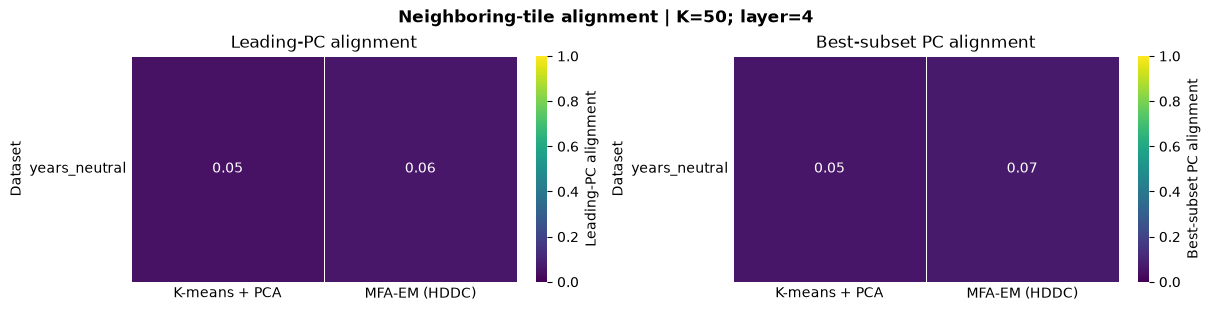

In [10]:
def plot_comparison_heatmap(ax, metric, table):
    values = table
    annotations = table.map(lambda value: f"{value:.2f}" if pd.notna(value) else "")
    cmap = "viridis"
    if metric == "Reconstruction MSE (validation)":
        cmap = "viridis_r"
        annotations = table.map(lambda value: f"{value:.2e}" if pd.notna(value) else "")
    vmin, vmax = (0, 1) if metric in ALIGNMENT_METRICS else (None, None)
    if metric == "Live / total components":
        values = table / K * 100
        vmin, vmax = 0, 100
        annotations = table.map(lambda value: f"{int(value)}/{K}" if pd.notna(value) else "")
    if metric in PC1_DENSITY_METRICS:
        limit = table.abs().max().max()
        limit = float(limit) if pd.notna(limit) and limit > 0 else 1.0
        cmap, vmin, vmax = "coolwarm", -limit, limit
    if not values.notna().any().any() and vmin is None:
        vmin, vmax = 0, 1
    sns.heatmap(values, ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,
                annot=annotations, fmt="", linewidths=0.5, linecolor="white",
                xticklabels=[MODEL_NAMES[model] for model in table.columns], yticklabels=table.index,
                cbar=bool(values.notna().any().any()),
                cbar_kws={"label": "Live components (%)" if metric == "Live / total components" else metric})
    ax.set_facecolor("#e9edf2")
    for row, col in np.argwhere(table.isna().to_numpy()):
        ax.text(col + 0.5, row + 0.5, "—", ha="center", va="center", color="#626b78")
    ax.set(title=metric, xlabel="", ylabel="Dataset")
    ax.tick_params(axis="both", labelrotation=0, length=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3),
                         squeeze=False, layout="constrained", facecolor="white")
for ax, metric in zip(axes.flat, ALIGNMENT_METRICS):
    plot_comparison_heatmap(ax, metric, comparison_tables[metric])
fig.suptitle(f"Neighboring-tile alignment | K={K}; layer={LAYER}", fontweight="bold")
plt.show()

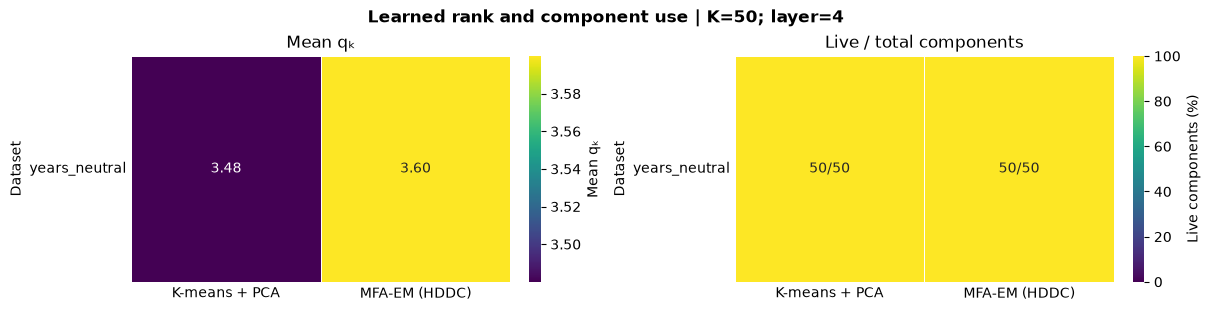

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3),
                         squeeze=False, layout="constrained", facecolor="white")
for ax, metric in zip(axes.flat, ["Mean qₖ", "Live / total components"]):
    plot_comparison_heatmap(ax, metric, comparison_tables[metric])
fig.suptitle(f"Learned rank and component use | K={K}; layer={LAYER}", fontweight="bold")
plt.show()

### Rank distribution

This uses saved `tile_alignment.per_tile` records, so no checkpoints or activations
are loaded. Histograms include only alignment-eligible tiles: live, positive rank, and PCA-valid for KMeans.
They therefore need not match the overall `Mean qₖ` above. No reference dimension is assumed.
Missing records are labeled separately from an empty eligible population.

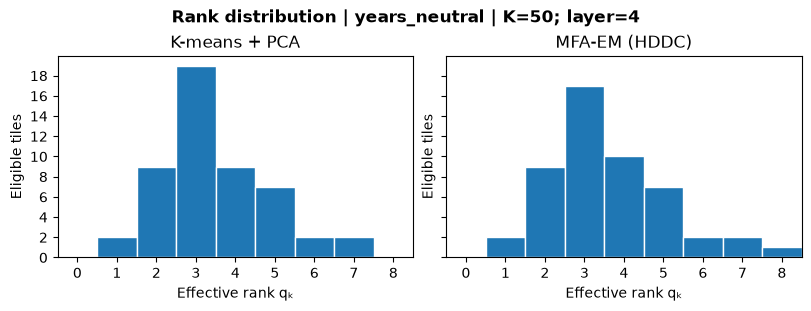

In [12]:
from matplotlib.ticker import MaxNLocator

rank_distributions = {}
for _, row in alignment_runs.iterrows():
    encoded = row.get("tile_alignment.per_tile")
    rank_distributions[row["model_kind"]] = (
        None if pd.isna(encoded) else np.array([tile["rank"] for tile in json.loads(encoded)], dtype=int)
    )
rank_max = max([1] + [int(values.max()) for values in rank_distributions.values()
                      if values is not None and values.size])
rank_bins = np.arange(rank_max + 2) - 0.5
fig, axes = plt.subplots(1, len(MODELS), figsize=(4 * len(MODELS), 3), sharex=True, sharey=True,
                         squeeze=False, layout="constrained", facecolor="white")
for ax, model in zip(axes.flat, MODELS):
    values = rank_distributions.get(model)
    if values is None or not values.size:
        ax.text(0.5, 0.5, "Unavailable tile records" if values is None else "No eligible tiles",
                transform=ax.transAxes, ha="center", va="center")
    else:
        ax.hist(values, bins=rank_bins, color="tab:blue", edgecolor="white")
    ax.set(title=MODEL_NAMES[model], xlabel="Effective rank qₖ", ylabel="Eligible tiles", xlim=(-0.5, rank_max + 0.5))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle(f"Rank distribution | {DATASET} | K={K}; layer={LAYER}", fontweight="bold")
plt.show()

## 5. PC1 density support

These scores use the saved validation activations as a density reference. PCA75 fits its global projection
only on training activations; ambient density uses the original coordinates. Select `PC1_DENSITY_SPACE`
in section 1. Reports from other spaces retain their other metrics, but their density scores are masked.

- **Median log PC1 retention** is primary: average density along the PC1 interval relative to center density.
- **Median log PC1 enrichment** compares retention with the arithmetic mean of matched random-direction retentions.
- Zero means ratio one; positive/negative values mean above/below one. Exponentiating a displayed value
  gives the exponentiated median log score used in the pilot reports. These scores are not probabilities.

Each metric uses a color scale centered at zero, with model columns sharing that scale.
Compare only matching saved validation splits, preprocessing, density coordinates, kNN settings, and random
baselines; the settings and population counts below help inspect this. Different centers, segment lengths,
and projected PC1 norms can affect scores. Higher enrichment alone does not establish better geometry.
Missing scores can mean disabled evaluation, another density space, or no eligible components.
Definitions: [PC1 density support](../docs/evaluation/unsupervised.md#pc1-density-support).


,dataset_id,model_kind,pc1_density.settings.pc1_density_space,pc1_density.density_dimension,pc1_density.projection.retained_variance_fraction,pc1_density.settings.pc1_density_neighbors,pc1_density.settings.pc1_density_random_directions,pc1_density.settings.pc1_density_seed,pc1_density.reference.points,pc1_density.eligible_components,pc1_density.excluded_components
report_path,,,,,,,,,,,
/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cache/sae-manifold/sae_manifold_years_neutral_llama31_8b_last/sae_manifold_years_neutral_hddc_em/hddc__years_neutral__l04__k50__q16__s42__f8b8b822/metrics.json,years_neutral,hddc,pca75,140,0.750774,20,32,42,1602,50,0
/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cache/sae-manifold/sae_manifold_years_neutral_llama31_8b_last/sae_manifold_years_neutral_kmeans_pca/kmeans__years_neutral__l04__k50__cattell__s42__a35cfbaa/metrics.json,years_neutral,kmeans,pca75,140,0.750774,20,32,42,1602,50,0


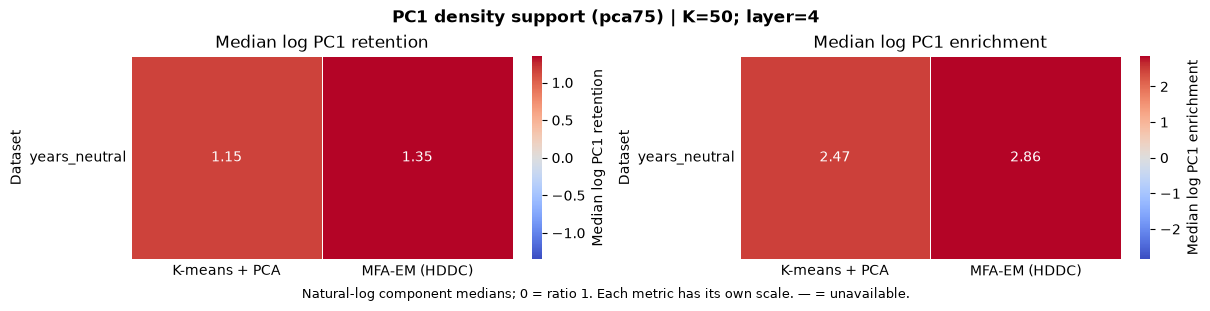

In [13]:
density_context_columns = [
    "pc1_density.settings.pc1_density_space", "pc1_density.density_dimension",
    "pc1_density.projection.retained_variance_fraction",
    "pc1_density.settings.pc1_density_neighbors",
    "pc1_density.settings.pc1_density_random_directions", "pc1_density.settings.pc1_density_seed",
    "pc1_density.reference.points", "pc1_density.eligible_components", "pc1_density.excluded_components",
]
display(alignment_runs.reindex(columns=["dataset_id", "model_kind", *density_context_columns]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3),
                         squeeze=False, layout="constrained", facecolor="white")
for ax, metric in zip(axes.flat, PC1_DENSITY_METRICS):
    plot_comparison_heatmap(ax, metric, comparison_tables[metric])
fig.suptitle(f"PC1 density support ({PC1_DENSITY_SPACE}) | K={K}; layer={LAYER}", fontweight="bold")
fig.supxlabel("Natural-log component medians; 0 = ratio 1. Each metric has its own scale. — = unavailable.",
              fontsize=9)
plt.show()


## 6. One heatmap for a report

Run the relevant selection and plotting cells first. Choose `"sweep"` for one K/threshold panel,
or `"comparison"` for a model comparison panel (alignment, PC1 density, reconstruction MSE, rank, or counts). Rendering reuses the dashboard scales and missing-value markers.
Edit the figure size/title and uncomment the export lines for a vector PDF or 300-dpi PNG.

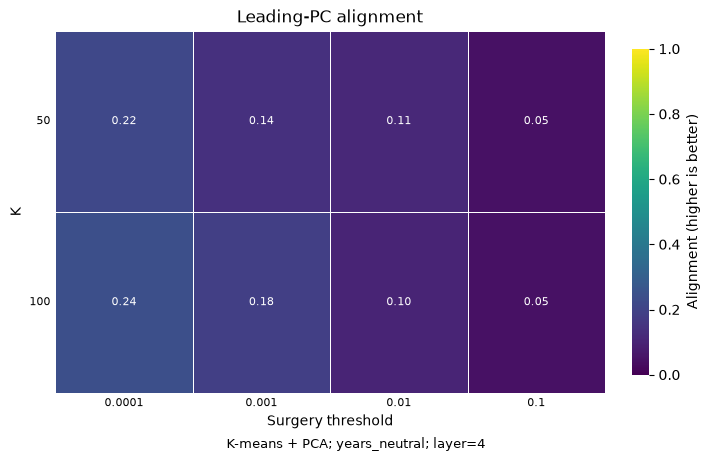

In [14]:
REPORT_SOURCE = "sweep"  # "sweep" or "comparison"
REPORT_METRIC = "Leading-PC alignment"  # e.g. "Median log PC1 retention"
REPORT_MODEL = next(iter(sweep_tables))  # Edit for a particular sweep panel.
REPORT_FIGSIZE = (7, 4.5)
REPORT_TITLE = None  # None preserves the metric title; "" removes it.

assert REPORT_SOURCE in {"sweep", "comparison"}
report_tables = sweep_tables[REPORT_MODEL] if REPORT_SOURCE == "sweep" else comparison_tables
assert REPORT_METRIC in (SWEEP_METRICS if REPORT_SOURCE == "sweep" else
                         ALIGNMENT_METRICS + PC1_DENSITY_METRICS + ["Mean qₖ", "Live / total components", "Reconstruction MSE (validation)"])
report_fig, report_ax = plt.subplots(figsize=REPORT_FIGSIZE, layout="constrained", facecolor="white")
if REPORT_SOURCE == "sweep":
    plot_sweep_heatmap(report_ax, REPORT_METRIC, report_tables[REPORT_METRIC], REPORT_MODEL)
    report_caption = f"{MODEL_NAMES[REPORT_MODEL]}; {DATASET}; layer={LAYER}"
    if REPORT_MODEL == "hddc":
        report_caption += f"; rank capacity={SWEEP_Q_CAPACITY}"
else:
    plot_comparison_heatmap(report_ax, REPORT_METRIC, report_tables[REPORT_METRIC])
    report_caption = f"K={K}; layer={LAYER}; thresholds={THRESHOLDS}"
if REPORT_METRIC in PC1_DENSITY_METRICS:
    report_caption += f"; density={PC1_DENSITY_SPACE}"
if REPORT_TITLE is not None:
    report_ax.set_title(REPORT_TITLE)
report_fig.supxlabel(report_caption, fontsize=9)

# report_dir = REPO_ROOT / "outputs" / "report_figures"
# report_dir.mkdir(parents=True, exist_ok=True)
# report_fig.savefig(report_dir / "unsupervised_heatmap.pdf", bbox_inches="tight")
# report_fig.savefig(report_dir / "unsupervised_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Held-out coverage over radius

This reuses section 3's selected runs, with model curves in one panel from
`heldout_distribution_coverage.coverage_curve`. Coverage is the fraction of independent test points within
radius r of a training-live centroid. Curves are full empirical CDFs, with no interpolation or subsampling.

Compare models only for matching test sources and preprocessing. Missing/disabled coverage is labeled. To add it, reevaluate with an independent
`test_shard_dir`, aggregate again, and rerun the notebook. Plotting does not launch evaluation.

In [15]:
COVERAGE_MODELS = MODELS
COVERAGE_CURVE_COLUMN = "heldout_distribution_coverage.coverage_curve"
assert COVERAGE_MODELS
coverage_runs = runs.loc[runs["model_kind"].isin(COVERAGE_MODELS)]
coverage_source_columns = [column for column in coverage_runs if column.startswith("heldout_distribution_coverage.source.")]
if coverage_source_columns:
    display(coverage_runs[["dataset_id", "model_kind", *coverage_source_columns]])
coverage_curves = {}
for _, row in coverage_runs.iterrows():
    encoded = row.get(COVERAGE_CURVE_COLUMN)
    if pd.isna(encoded):
        continue
    curve = pd.DataFrame(json.loads(encoded))
    assert not curve.empty and {"radius", "fraction"}.issubset(curve), "Expected a full empirical coverage curve."
    coverage_curves[row["model_kind"]] = curve
print(f"Selected {len(coverage_curves)} empirical coverage curves at K={K}.")

,dataset_id,model_kind,heldout_distribution_coverage.source.d_model,heldout_distribution_coverage.source.drop_prefix,heldout_distribution_coverage.source.layer,heldout_distribution_coverage.source.num_points,heldout_distribution_coverage.source.num_rows,heldout_distribution_coverage.source.shard_dir,heldout_distribution_coverage.source.subset_spec,heldout_distribution_coverage.source.window
report_path,,,,,,,,,,
/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cache/sae-manifold/sae_manifold_years_neutral_llama31_8b_last/sae_manifold_years_neutral_hddc_em/hddc__years_neutral__l04__k50__q16__s42__f8b8b822/metrics.json,years_neutral,hddc,4096,0,4,4004,4004,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...,NaN,1
/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cache/sae-manifold/sae_manifold_years_neutral_llama31_8b_last/sae_manifold_years_neutral_kmeans_pca/kmeans__years_neutral__l04__k50__cattell__s42__a35cfbaa/metrics.json,years_neutral,kmeans,4096,0,4,4004,4004,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...,NaN,1


Selected 2 empirical coverage curves at K=50.


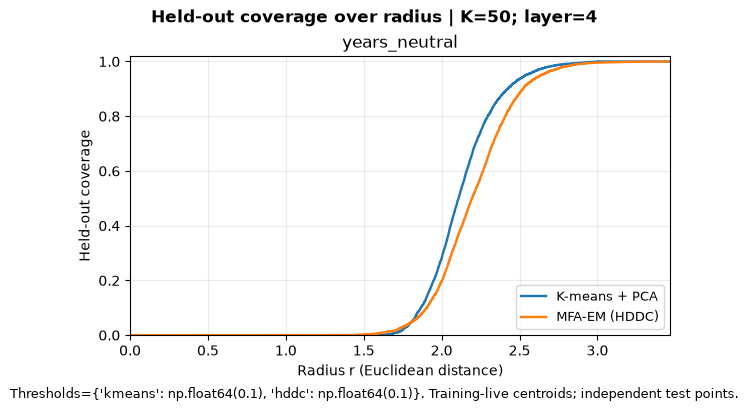

In [16]:
coverage_colors = dict(zip(MODEL_NAMES, plt.get_cmap("tab10").colors))
coverage_fig, ax = plt.subplots(figsize=(6, 4), layout="constrained", facecolor="white")
available = {model: coverage_curves[model] for model in COVERAGE_MODELS if model in coverage_curves}
max_radius = max([0.0] + [curve["radius"].max() for curve in available.values()])
radius_limit = 1.02 * max_radius if max_radius > 0 else 1.0
for model, curve in available.items():
    ax.step(np.r_[0.0, curve["radius"].to_numpy(), radius_limit],
            np.r_[0.0, curve["fraction"].to_numpy(), 1.0], where="post",
            label=MODEL_NAMES[model], color=coverage_colors[model], linewidth=1.7)
missing = [MODEL_NAMES[model] for model in COVERAGE_MODELS if model not in available]
if missing:
    ax.text(0.03, 0.95, "Coverage unavailable: " + ", ".join(missing),
            transform=ax.transAxes, va="top", fontsize=9, wrap=True)
ax.set(title=DATASET, xlabel="Radius r (Euclidean distance)", ylabel="Held-out coverage",
       xlim=(0, radius_limit), ylim=(0, 1.02))
ax.grid(alpha=0.25)
if available:
    ax.legend(fontsize=9, loc="lower right")
coverage_fig.suptitle(f"Held-out coverage over radius | K={K}; layer={LAYER}", fontweight="bold")
coverage_fig.supxlabel(f"Thresholds={THRESHOLDS}. Training-live centroids; independent test points.", fontsize=9)
# coverage_fig.savefig(REPO_ROOT / "outputs" / "unsupervised_coverage.pdf", bbox_inches="tight")
plt.show()